# 03 — Resultados, Métricas, Gráficos e Avaliação Sem Novo Treinamento

Este notebook apresenta todas as tabelas comparativas, métricas por classe, curvas de aprendizagem, matrizes de confusão, efeito da resolução na CNN, análise de erros do melhor modelo obrigatório e avaliação reprodutível direta dos checkpoints salvos em `models/`.

In [1]:
import json
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

BASE_DIR = Path('..').resolve()
sys.path.append(str(BASE_DIR / 'src'))

df_comp = pd.read_csv(BASE_DIR / 'results' / 'tabela_comparativa_geral.csv')
display(df_comp)

,Experimento,Modelo,Resolucao_LxA,Pesos_Classe,Parametros,Tamanho_MB,Epocas_Melhor_Total,Tempo_Total_s,Tempo_Medio_Epoca_s,Pico_RAM_MB,Val_Acc,Val_F1_Macro,Teste_Acc,Teste_F1_Macro
0,"Exp 1: MLP (128×96, Sem Pesos)",MLP,128 × 96,Não,9471110,36.132,12/20,62.04,3.102,1012.62,0.4406,0.333,0.3842,0.2941
1,"Exp 2: MLP (128×96, Com Pesos)",MLP,128 × 96,Sim,9471110,36.132,6/14,43.40,3.100,1012.83,0.2797,0.1987,0.2895,0.2005
2,"Exp 3: CNN (128×96, Sem Pesos)",CNN,128 × 96,Não,28358,0.117,35/35,102.70,2.934,895.84,0.7414,0.7229,0.7237,0.6754
3,"Exp 4: CNN (128×96, Com Pesos)",CNN,128 × 96,Sim,28358,0.117,33/35,101.11,2.889,729.60,0.7309,0.7187,0.7053,0.6833
4,"Exp 5: CNN (256×192, Sem Pesos)",CNN,256 × 192,Não,28358,0.117,26/30,340.62,11.354,2188.65,0.7177,0.6641,0.7184,0.6694
5,"Exp 6: CNN (512×384, Sem Pesos)",CNN,512 × 384,Não,28358,0.117,6/12,708.35,59.029,6601.80,0.6464,0.5723,0.5684,0.4992
6,"Exp 7 (Bônus): YOLO11n-cls (224×224, Transfer ...",YOLO11n-cls (Bonus),224 × 224,Não (Pré-treinado),1538790,3.050,20/20,2404.90,120.245,474.45,0.9208,-,0.9316,0.9198


In [2]:
df_cls = pd.read_csv(BASE_DIR / 'results' / 'tabela_metricas_por_classe.csv')
display(df_cls)

,Experimento,Classe,Precisao,Recall,F1,Suporte
0,"Exp 1: MLP (128×96, Sem Pesos)",glass,0.2712,0.2105,0.2370,76
1,"Exp 1: MLP (128×96, Sem Pesos)",paper,0.3010,0.6966,0.4203,89
2,"Exp 1: MLP (128×96, Sem Pesos)",cardboard,0.6724,0.6500,0.6610,60
3,"Exp 1: MLP (128×96, Sem Pesos)",plastic,0.5088,0.3973,0.4462,73
4,"Exp 1: MLP (128×96, Sem Pesos)",metal,0.0000,0.0000,0.0000,62
5,"Exp 1: MLP (128×96, Sem Pesos)",trash,0.0000,0.0000,0.0000,20
6,"Exp 2: MLP (128×96, Com Pesos)",glass,0.2270,0.8421,0.3575,76
7,"Exp 2: MLP (128×96, Com Pesos)",paper,0.5000,0.0112,0.0220,89
8,"Exp 2: MLP (128×96, Com Pesos)",cardboard,0.4824,0.6833,0.5655,60
9,"Exp 2: MLP (128×96, Com Pesos)",plastic,0.0000,0.0000,0.0000,73


## Avaliação Reprodutível dos Modelos Salvos (Sem Novo Treinamento)

In [3]:
from evaluate_saved_models import evaluate_pytorch_checkpoints
evaluate_pytorch_checkpoints()

AVALIAÇÃO REPRODUTÍVEL SEM NOVO TREINAMENTO (CONJUNTO DE TESTE: 380 IMAGENS)


exp1_mlp_128x96_sem_pesos        | Melhor Época: 12 | Teste Acc: 0.3842 | Teste F1 Macro: 0.2941


exp2_mlp_128x96_com_pesos        | Melhor Época: 06 | Teste Acc: 0.2895 | Teste F1 Macro: 0.2005


exp3_cnn_128x96_sem_pesos        | Melhor Época: 35 | Teste Acc: 0.7237 | Teste F1 Macro: 0.6754


exp4_cnn_128x96_com_pesos        | Melhor Época: 33 | Teste Acc: 0.7053 | Teste F1 Macro: 0.6833


exp5_cnn_256x192_sem_pesos       | Melhor Época: 26 | Teste Acc: 0.7184 | Teste F1 Macro: 0.6694


exp6_cnn_512x384_sem_pesos       | Melhor Época: 06 | Teste Acc: 0.5684 | Teste F1 Macro: 0.4992


exp7_yolo11n_cls_bonus           | Transfer Learning | Teste Acc: 0.9316 | Teste F1 Macro: 0.9198


## Painéis Gráficos Obrigatórios e Extensão YOLO

Exibindo: fig1_distribuicao_classes.png


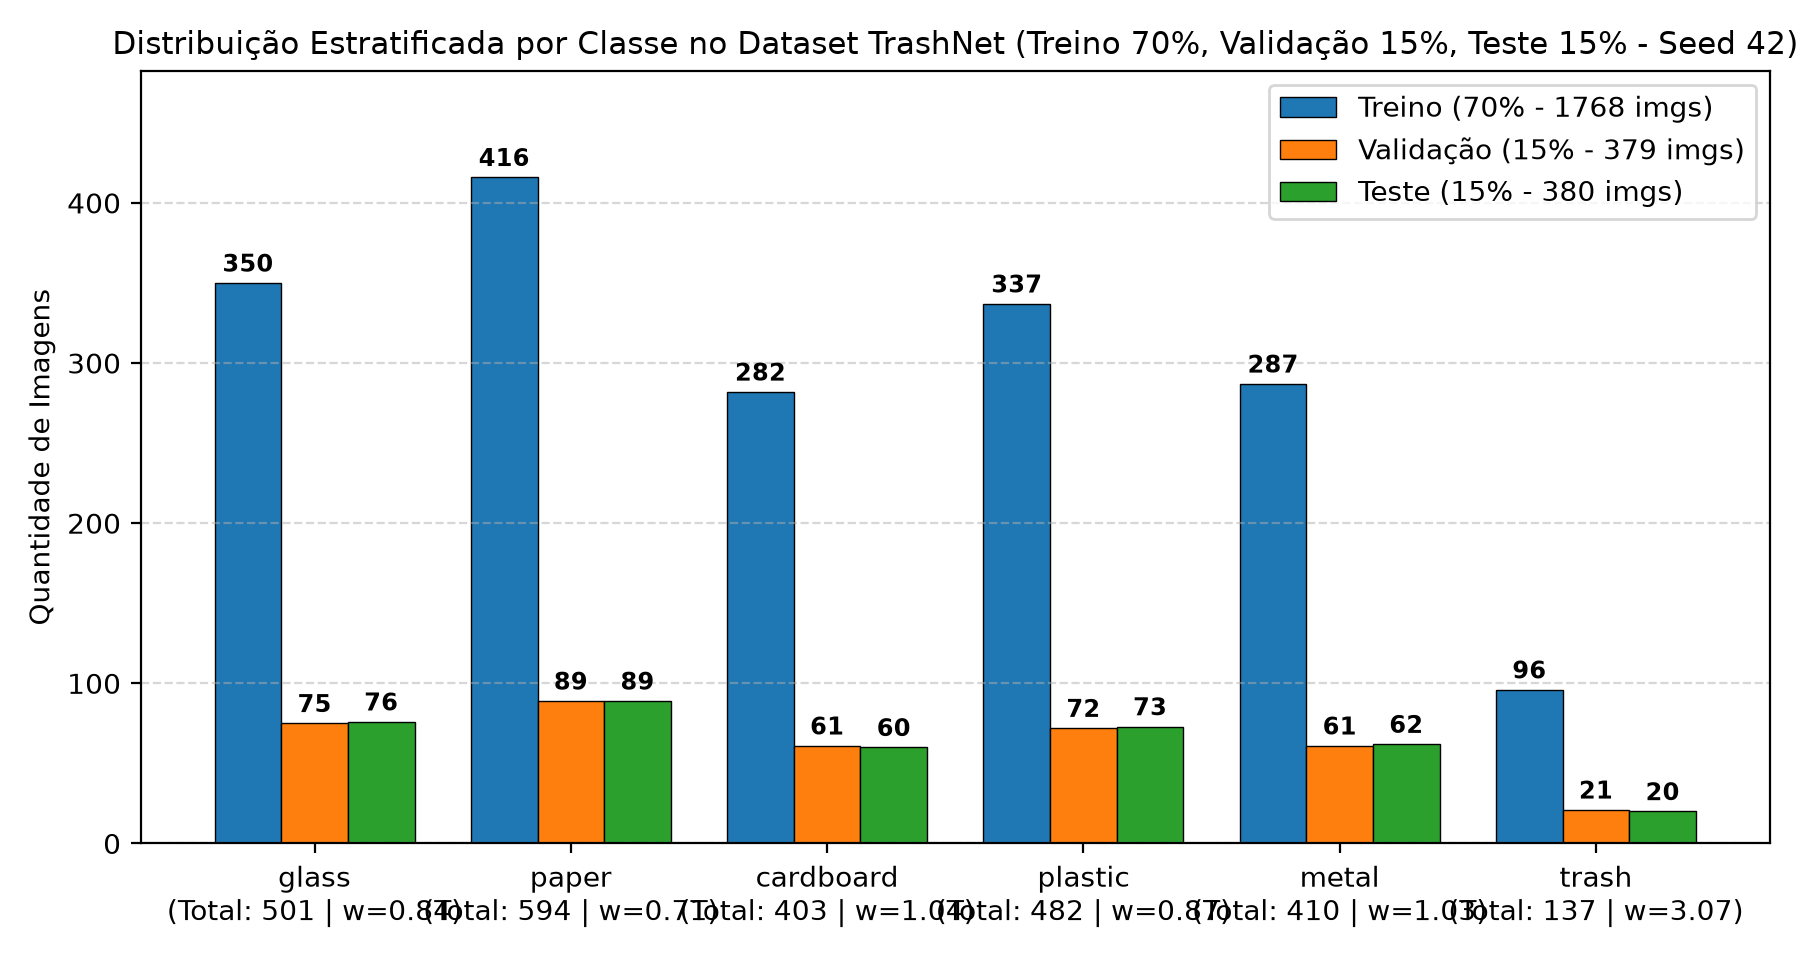

Exibindo: fig2_exemplos_classes.png


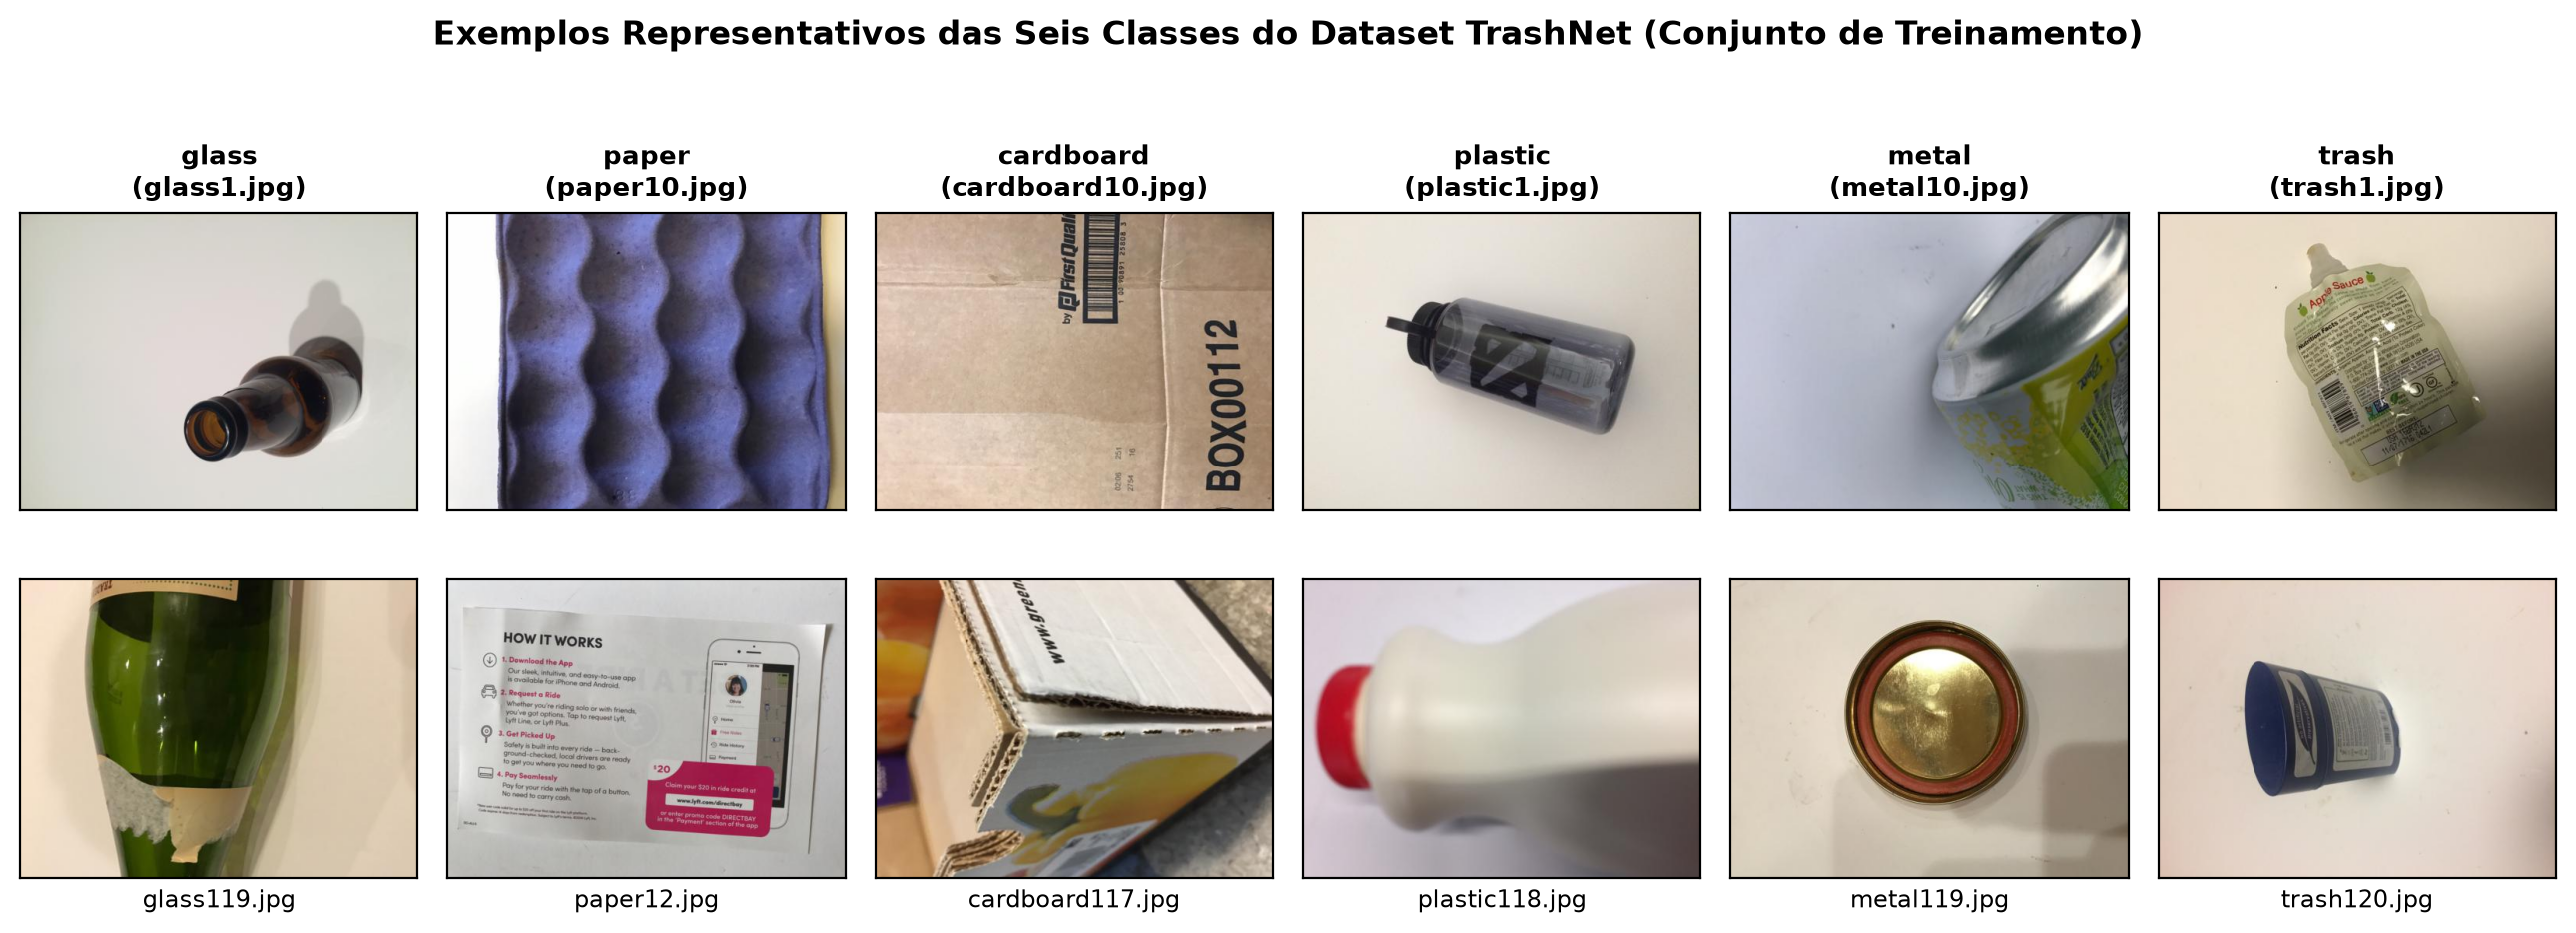

Exibindo: fig3_comparacao_resolucoes.png


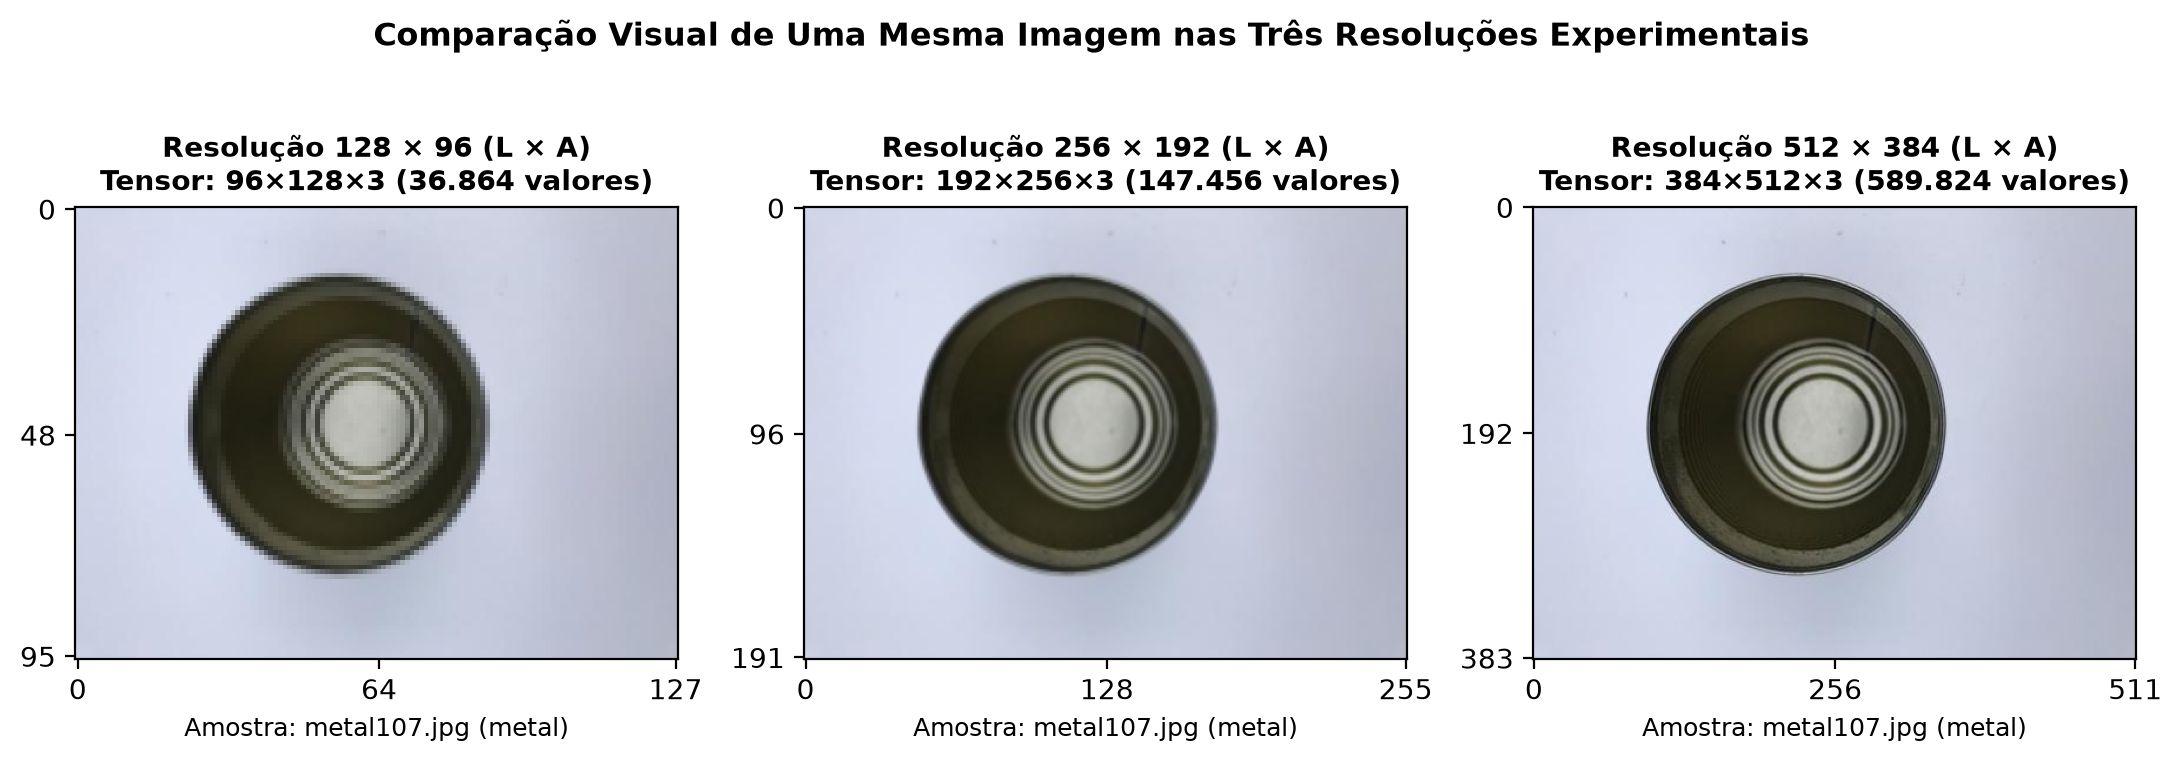

Exibindo: fig4_curvas_aprendizagem_6exp.png


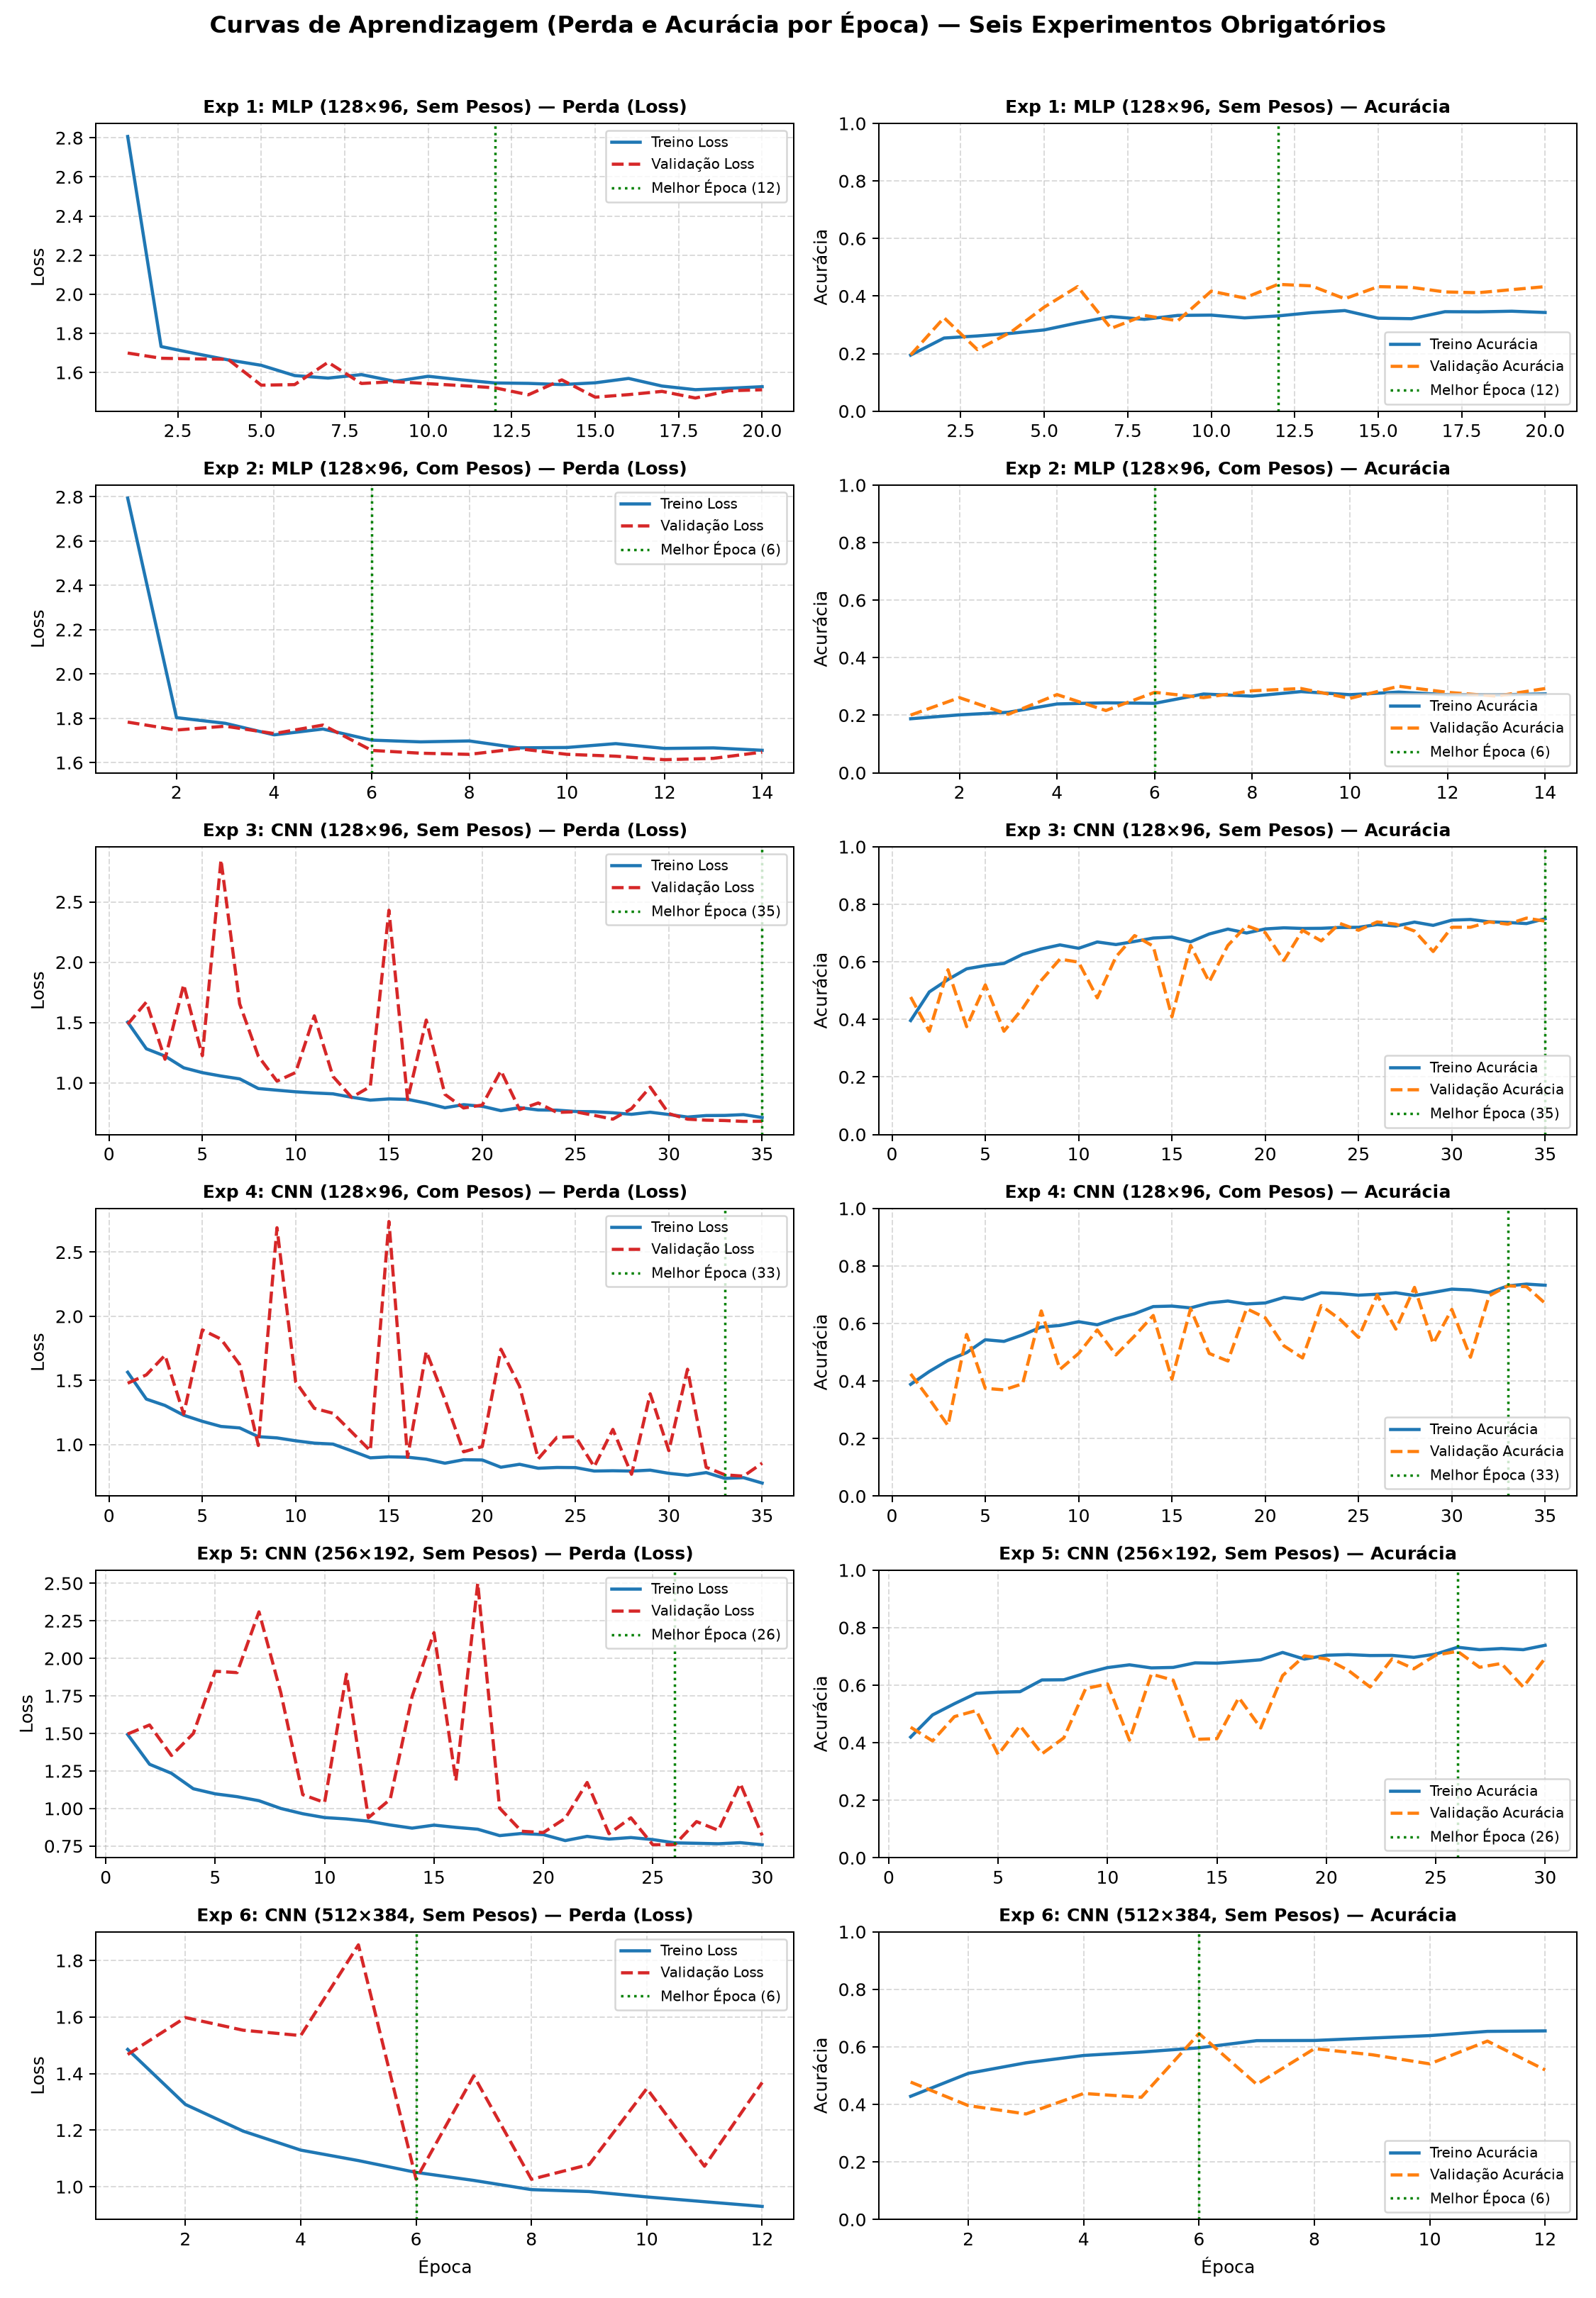

Exibindo: fig5_matrizes_confusao_6exp.png


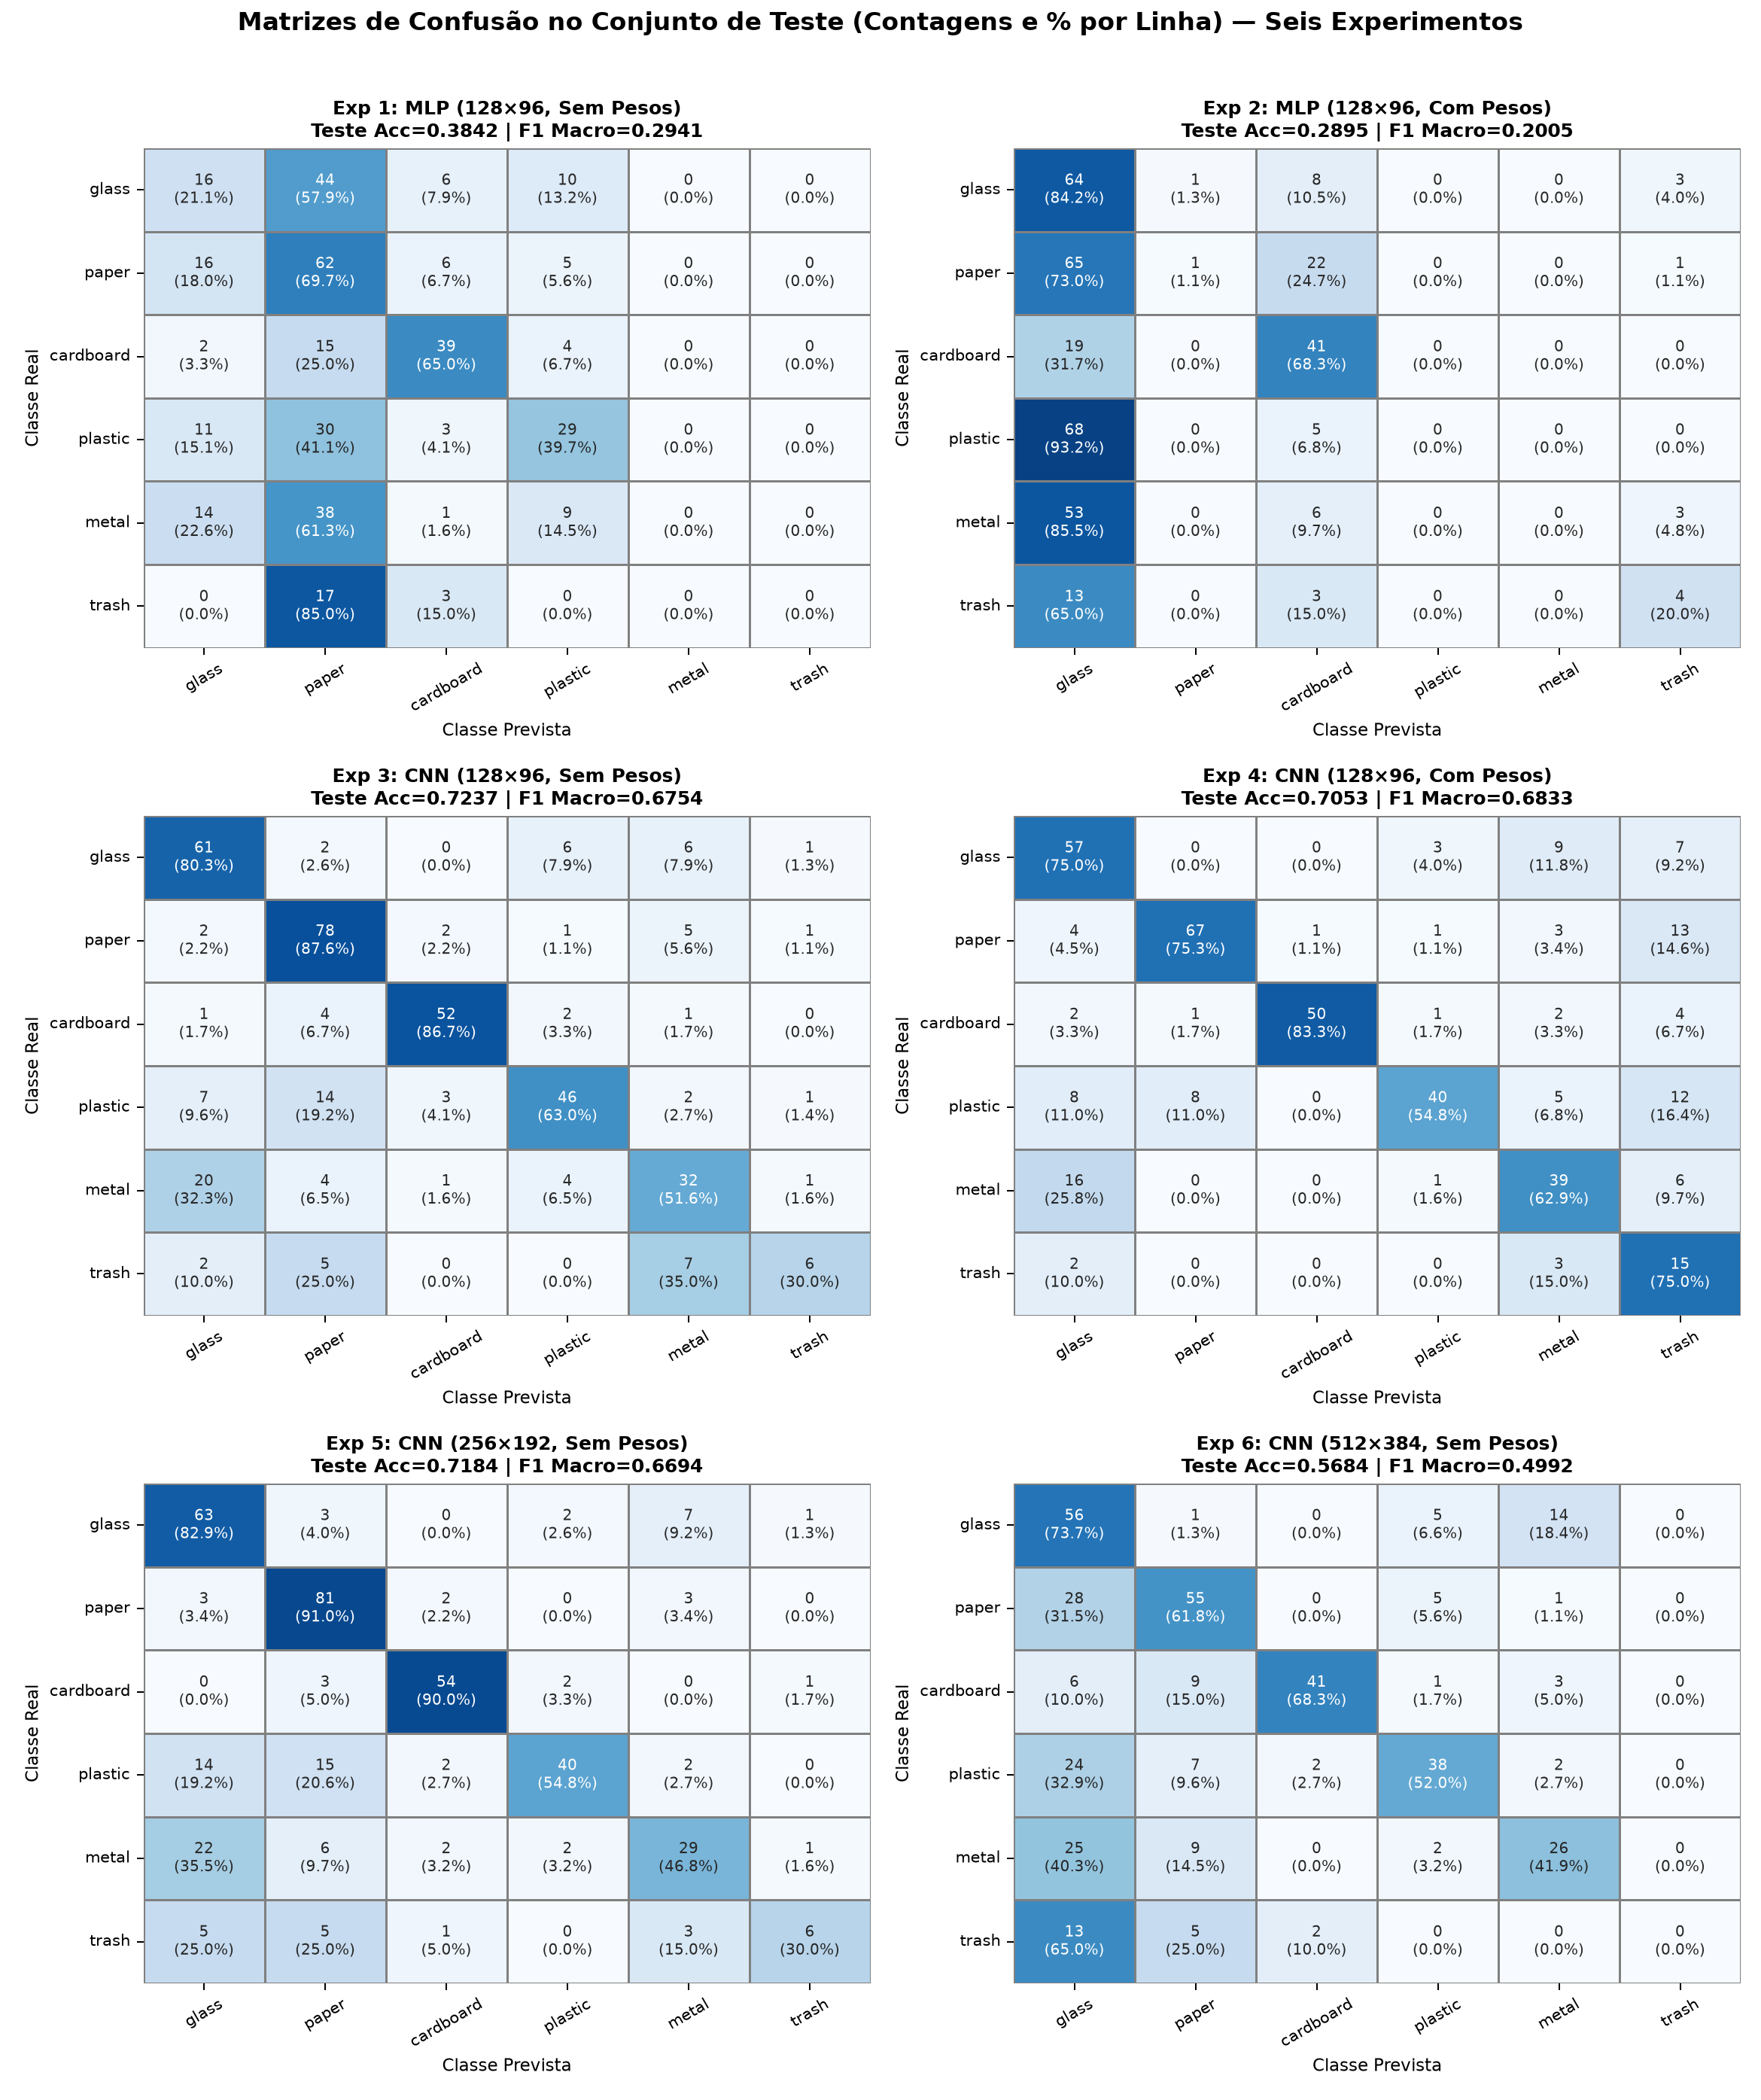

Exibindo: fig6_efeito_resolucao_cnn.png


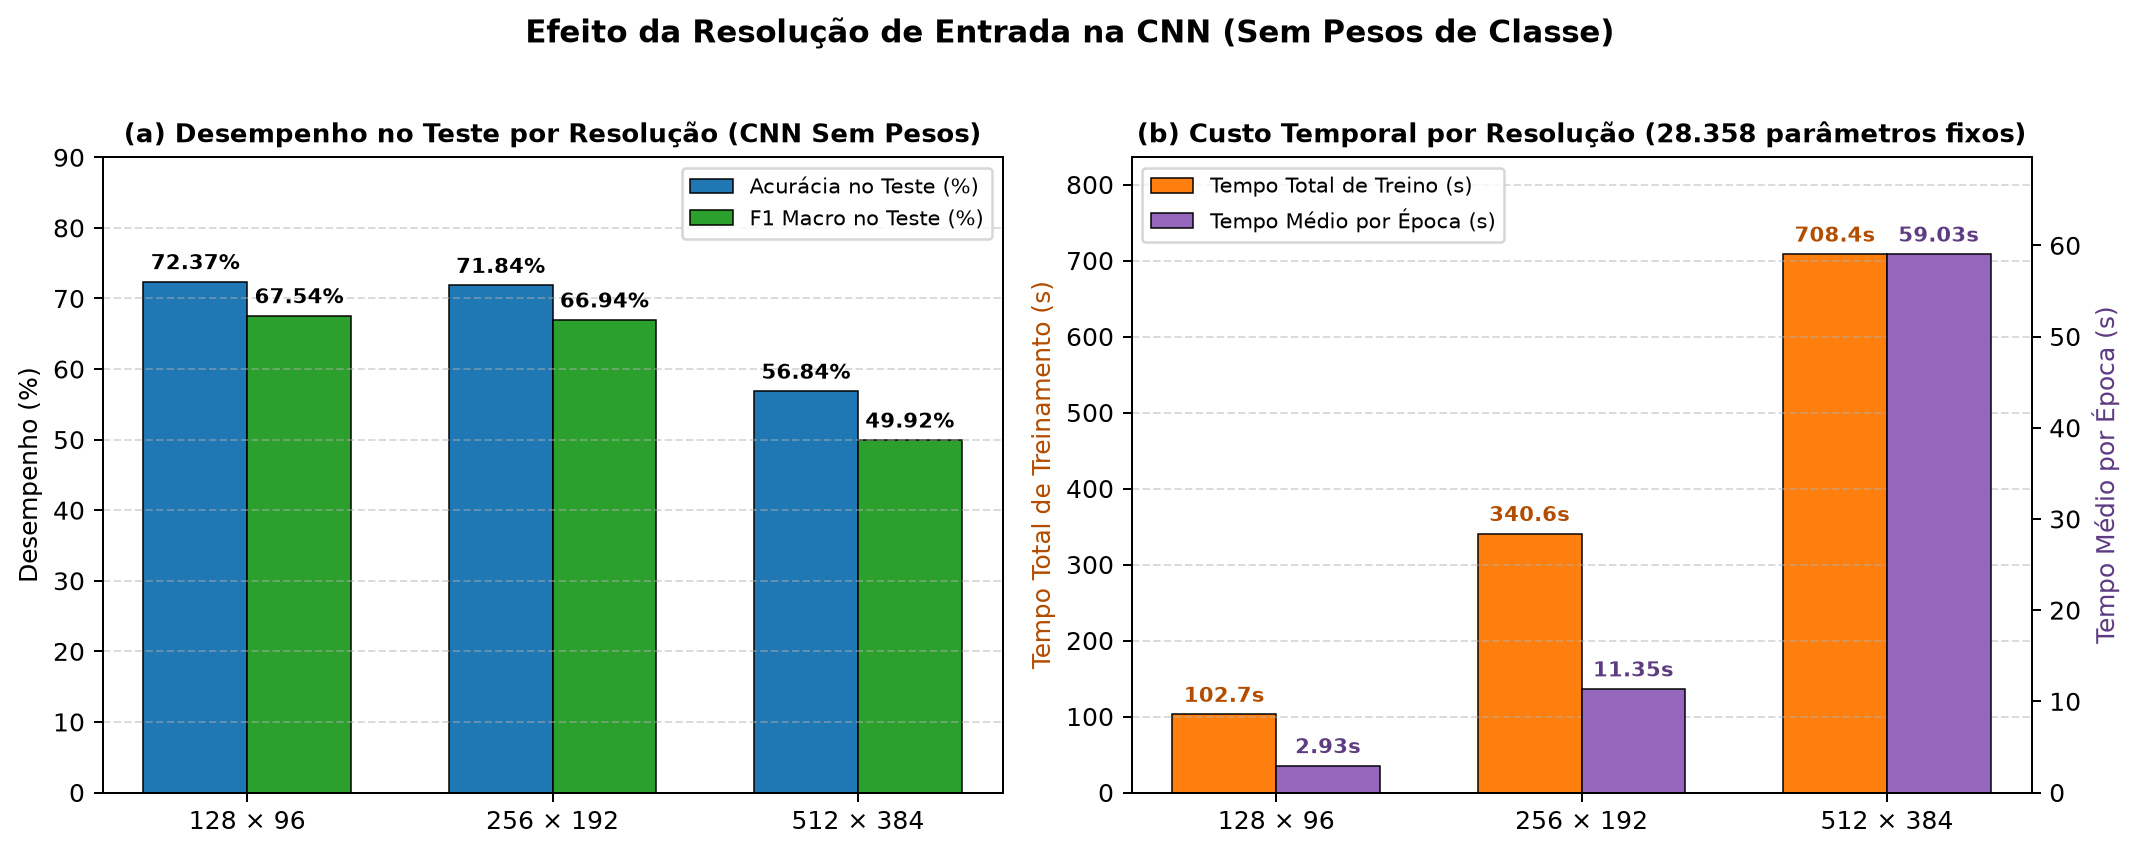

Exibindo: fig7_analise_erros_melhor_modelo.png


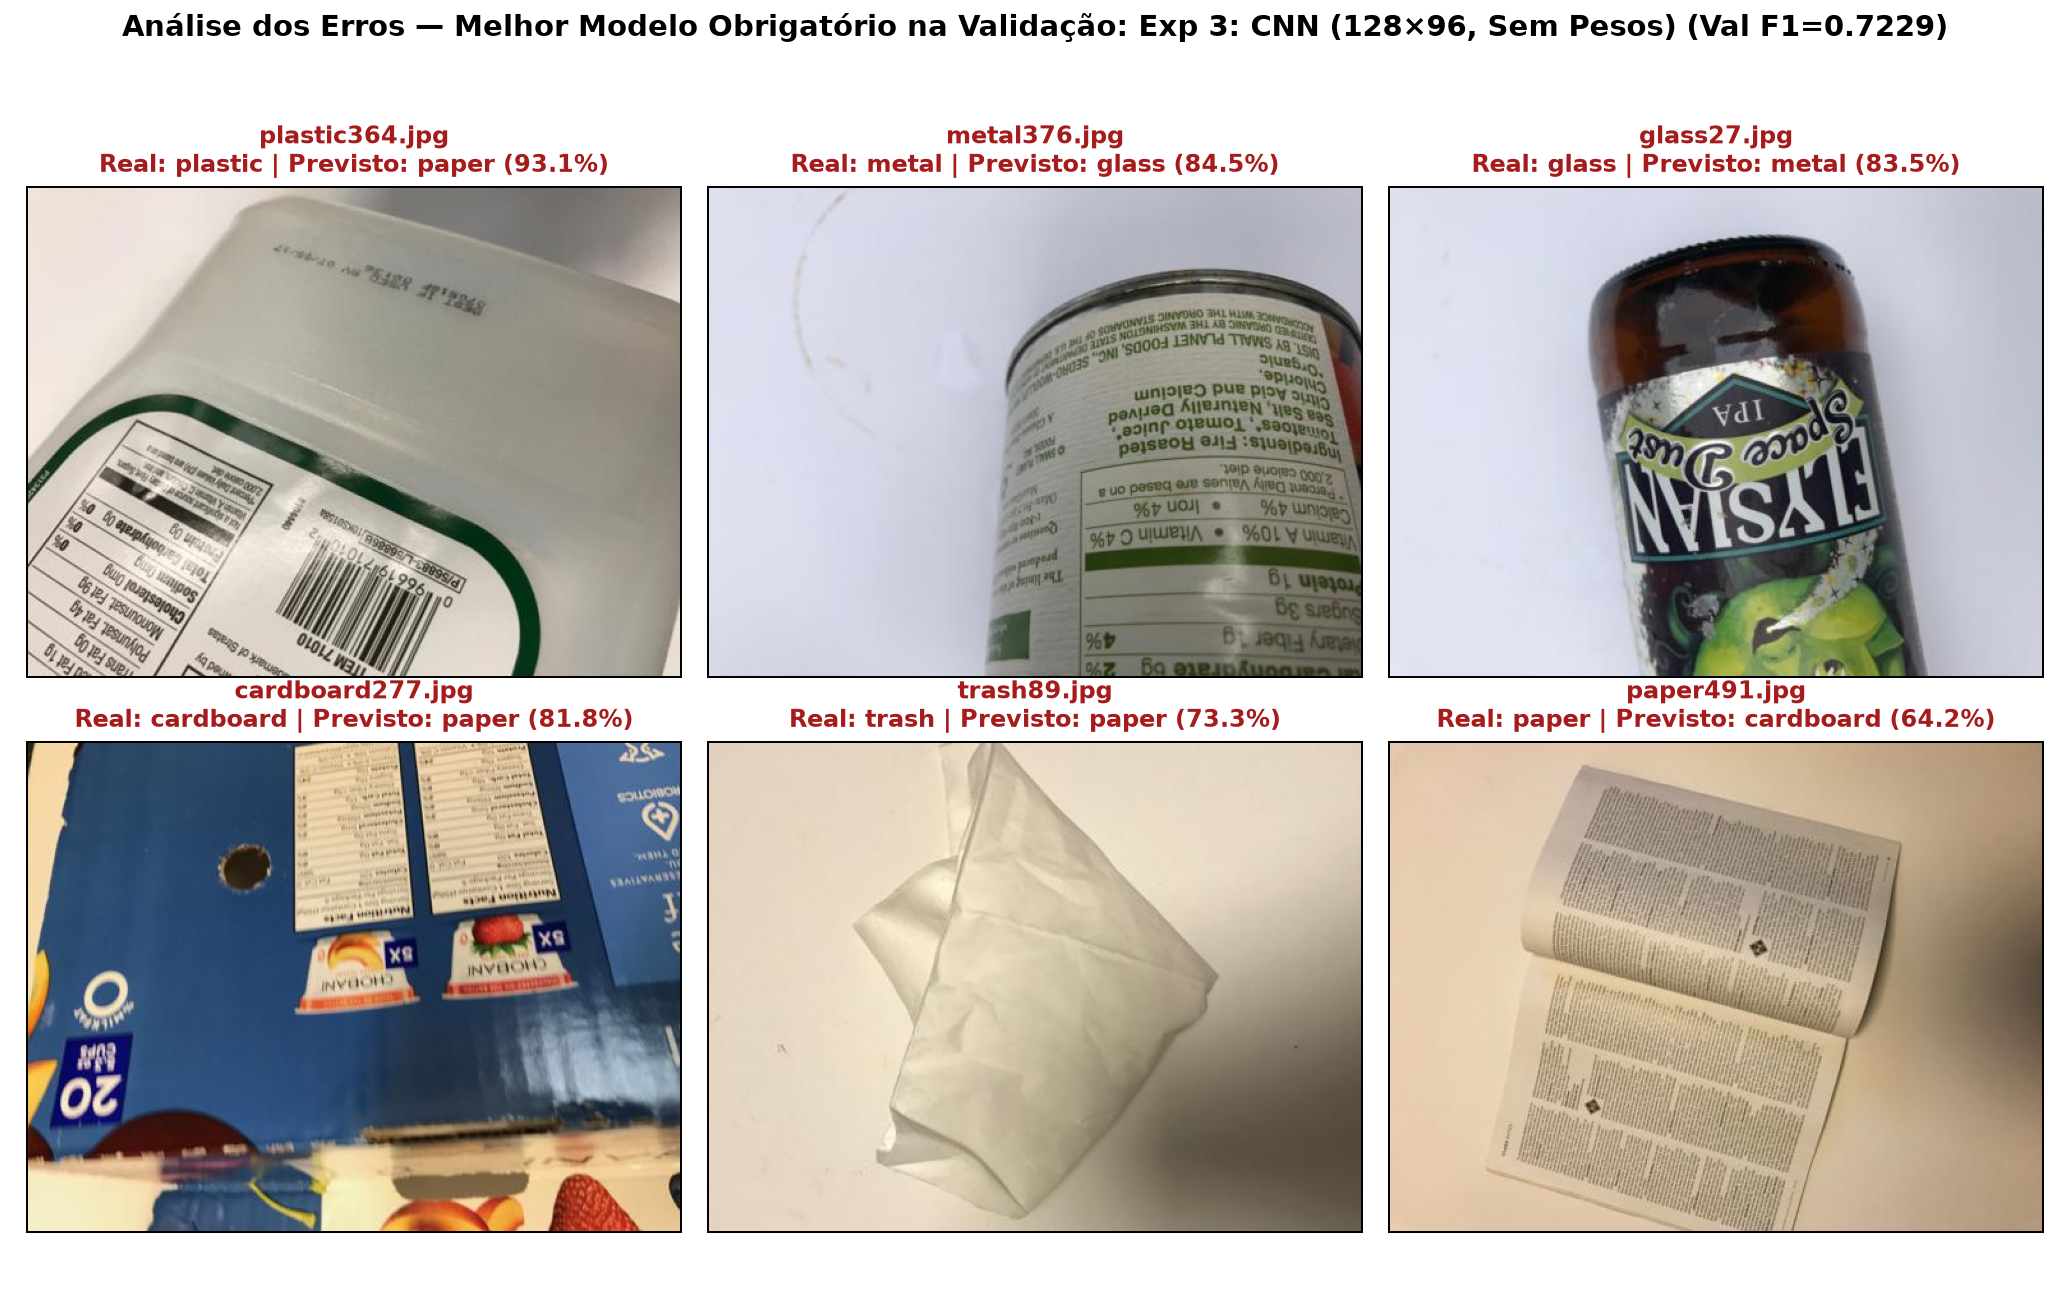

Exibindo: fig8_yolo_bonus_avaliacao.png


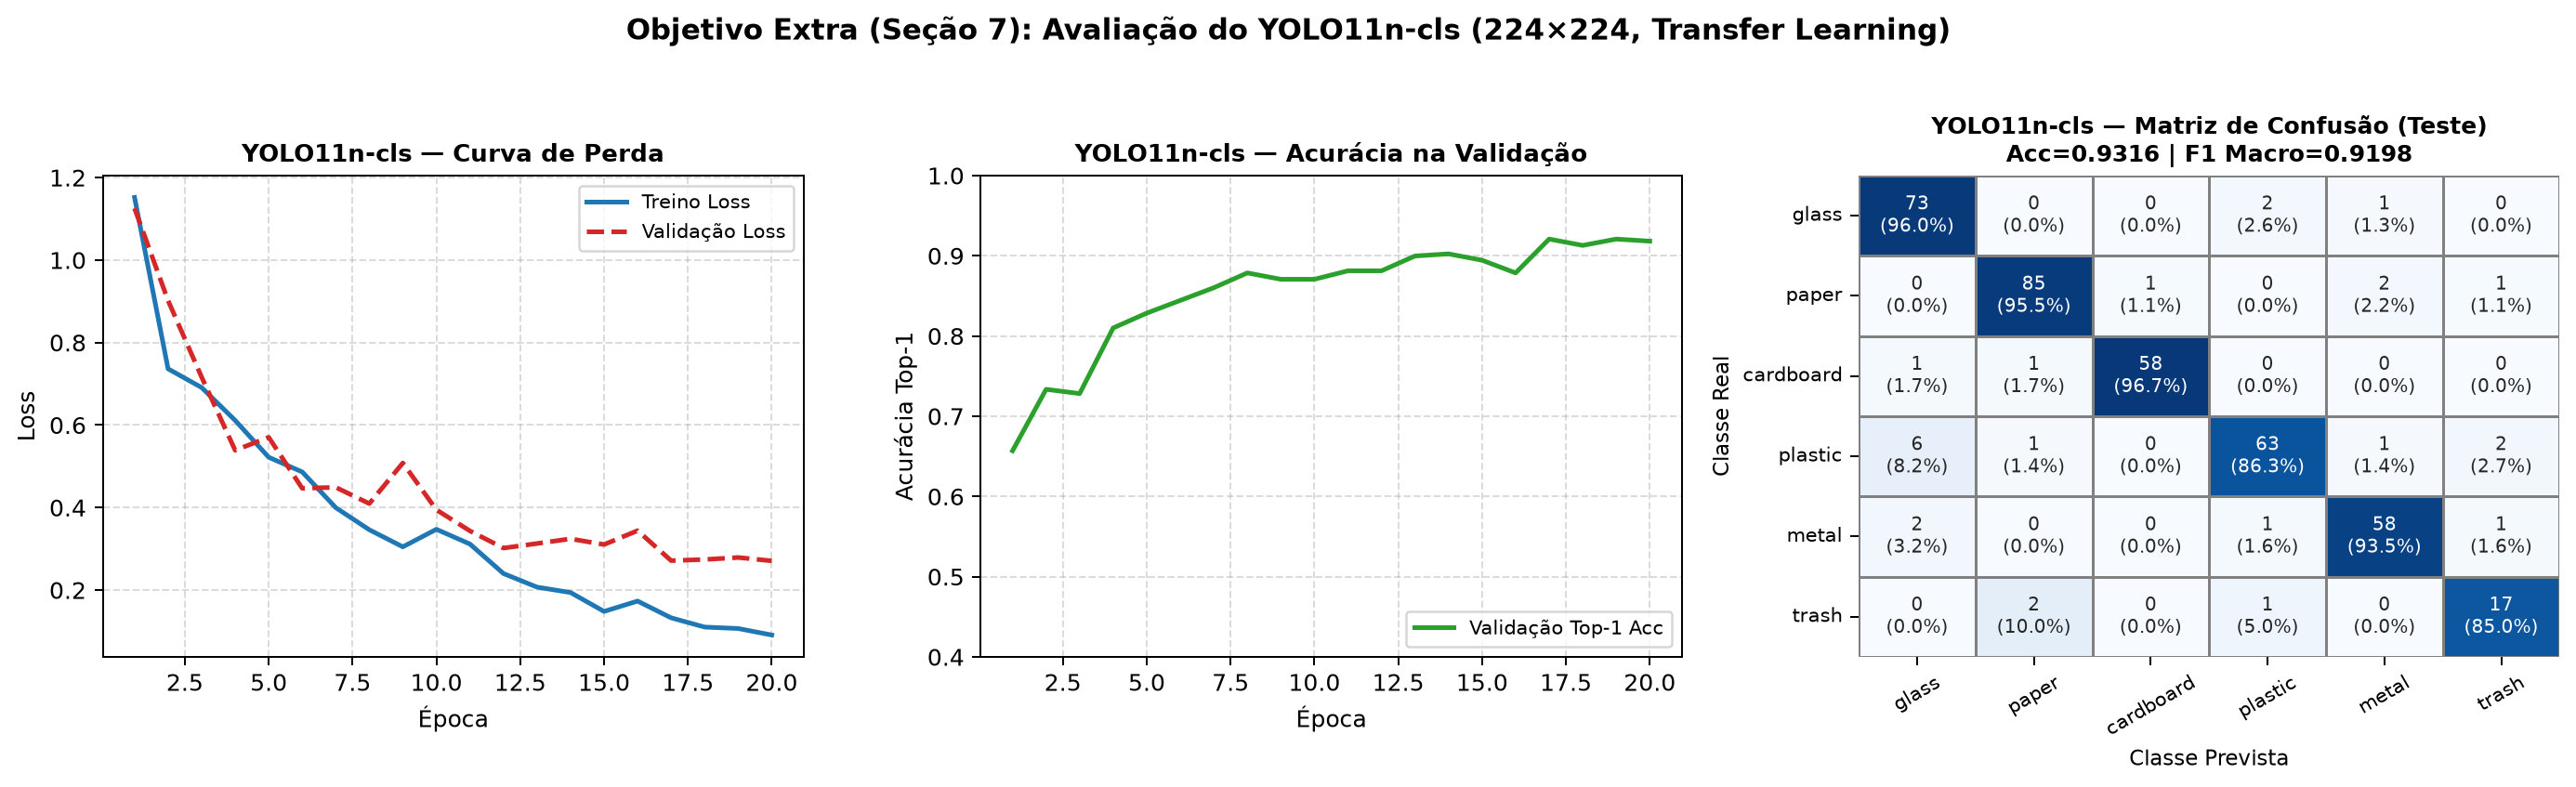

In [4]:
figs = [
    'fig1_distribuicao_classes.png',
    'fig2_exemplos_classes.png',
    'fig3_comparacao_resolucoes.png',
    'fig4_curvas_aprendizagem_6exp.png',
    'fig5_matrizes_confusao_6exp.png',
    'fig6_efeito_resolucao_cnn.png',
    'fig7_analise_erros_melhor_modelo.png',
    'fig8_yolo_bonus_avaliacao.png',
]
for fig in figs:
    print('Exibindo:', fig)
    display(Image(filename=str(BASE_DIR / 'results' / 'figures' / fig)))